# NN-09 · Hyper-Connections at small scale — GPU runner (Kaggle or Colab)

Runs the study's code on a **free cloud GPU** and keeps the results in that service's storage. Nothing here needs the project
repo: the code is embedded in this notebook (snapshot below).

**Where to run it (both are free)**
- **Kaggle (recommended).** A weekly GPU quota (about 30 hours is commonly reported; your profile shows yours), **two T4 GPUs at
  once**, and *Save Version ▸ Save & Run All (Commit)* runs on Kaggle's servers for up to 12 h, so you can close the browser.
  It needs a phone-verified account. In the right-hand *Session options* set **Accelerator = GPU T4 x2** and **Internet = On**.
- **Colab.** Also works (results go to your Google Drive), but the free tier has no background mode and fewer, less
  predictable hours. One GPU only.

**How to use**
1. **First run = a cost check, about 15 minutes, nothing big is trained.** Leave the settings as they are (`PLAN = pilot`,
   `LAUNCH` off) and press *Run all*. It runs the test-suite, one tiny training run, and a profile of your GPU(s) (step time,
   memory and speed of every model × connection). Then it prints how many GPU-hours the pilot plan needs and what other epoch /
   seed choices would cost. Send back the printed output, then **stop the session** so it does not use up quota.
2. **Real run, only after the plan is agreed:** tick **LAUNCH** (and set EPOCHS / SEEDS). Kaggle: *Save Version ▸ Save & Run All
   (Commit)*, which switches LAUNCH on by itself. Colab: *Run all*. Every GPU gets its own worker, and the notebook pauses cleanly after about **MAX_HOURS** hours so
   nothing is lost when the 12 h session limit hits.
3. **Continuing:** finished runs are skipped and paused ones resume. Colab: just *Run all* again. Kaggle: first add the last
   version's output as input (*Add Input ▸ Notebook Output Files ▸ this notebook*); the notebook copies the earlier progress
   back. `PLAN = smoke` repeats the 2-epoch pipeline check, `tier1` is the full 144-run matrix.

**What you get back**
- the results zip `<DRIVE_FOLDER>/<plan>_raw.zip` (Colab: in your Drive; Kaggle: in the notebook's *Output* tab): unzip it into
  the project's `results/raw/`;
- the cost table `<DRIVE_FOLDER>/timing/cost_<gpu>__<plan>.csv` (it is also printed) and, once runs have finished, the tables and
  figures built from them (`<plan>_analysis.zip`). **BUILD_PAPER** (off by default) also compiles the paper draft.

**Honest limits**
- `EPOCHS` has no approved value yet: D7/D8 say 200 (provisional) and the P4 plan decides. The default 30 is only a placeholder.
- D6 (how a 10 % subset is trained) is still PENDING; **P10_STEPS = same_steps** is the recommended default, not a decision.
- Training is fp32. Whether to allow mixed precision on these GPUs is an open question for the project lead.
- The two-GPU workers, the Kaggle restore and the time-limit pause have been checked with stand-ins only; the first real run on
  Kaggle is their first real test. If a cell prints a red error, send the output back.
- Pilot / tier1 results are real logs of the study's pipeline, but nothing here is a conclusion.

In [1]:
#@title 1 · What to run  { display-mode: "form" }
PLAN = "pilot"            #@param ["smoke", "pilot", "tier1"]
EPOCHS = 30               #@param {type:"integer"}
SEEDS = "0"               #@param {type:"string"}
P10_STEPS = "same_steps"  #@param ["same_steps", "same_epochs"]
CKPT_EVERY = 1            #@param {type:"integer"}
RUN_TESTS = True          #@param {type:"boolean"}
RUN_TIMING = True         #@param {type:"boolean"}
LAUNCH = False            #@param {type:"boolean"}
MAX_HOURS = 11            #@param {type:"number"}
USE_ALL_GPUS = True       #@param {type:"boolean"}
WEEKLY_GPU_HOURS = 30     #@param {type:"number"}
RUN_ANALYSIS = True       #@param {type:"boolean"}
BUILD_PAPER = False       #@param {type:"boolean"}
DRIVE_FOLDER = "nn09"     #@param {type:"string"}
# PLAN: smoke = all 24 model x connection pairs for 2 tiny epochs; pilot = ResNet-20/56 + ViT-Tiny-6, 4 connections,
#       CIFAR-100 100% and 10%, SEEDS, EPOCHS; tier1 = the full 6 models x 4 connections x 2 data settings, SEEDS, EPOCHS.
# LAUNCH: off = only check and price the plan (the safe default); on = start the real runs.
# MAX_HOURS: both services end a session after 12 h; the runs pause cleanly (progress saved) once this many hours have passed
#       since the notebook started, leaving time to package the results.   USE_ALL_GPUS: one worker per GPU (Kaggle T4 x2 = 2).
# WEEKLY_GPU_HOURS: your free quota per week (Kaggle shows it on your profile); only used to print how many weeks a plan takes.
# SEEDS: "0" or "0,1,2".   CKPT_EVERY: resume-checkpoint cadence in epochs (raise to 5 if Drive writes are slow).
# RUN_ANALYSIS: after the runs, build tables T1-T4 and figures F1-F7 from the finished runs. BUILD_PAPER: also install LaTeX
#       (2-4 min) and compile the paper draft from them; off by default.
# DRIVE_FOLDER: no spaces; the Drive folder on Colab, the output folder on Kaggle. One results folder is used per plan and
#       epoch count (e.g. pilot_e30) so plans never mix.

In [2]:
#@title Project code snapshot (generated by scripts/make_colab_notebook.py; do not edit)  { display-mode: "form" }
SNAPSHOT_COMMIT = "481ea54cbf18816d53a2f3bd1391f87b2e92809b"
SNAPSHOT_B64 = "".join([
    "...",
])

In [3]:
# 3 · Setup: GPUs, storage, project code, helper
import base64, glob, io, json, os, pathlib, shutil, subprocess, sys, time, urllib.request, zipfile
import torch

SESSION_START = time.time()
if os.path.isdir("/kaggle/working"):               # test for Kaggle first: its image also ships a google.colab package that cannot mount Drive
    PLATFORM = "kaggle"
else:
    try:
        from google.colab import drive
        PLATFORM = "colab"
    except ImportError:
        PLATFORM = "other"
IN_COLAB = PLATFORM == "colab"
# Kaggle "Save & Run All (Commit)" is the real run (papermill writes __notebook__.ipynb into the working folder); the
# interactive "Run all" stays a cost check
KAGGLE_BATCH = PLATFORM == "kaggle" and (os.environ.get("KAGGLE_KERNEL_RUN_TYPE") == "Batch" or os.path.exists("__notebook__.ipynb"))
if KAGGLE_BATCH and not LAUNCH:
    LAUNCH = True
    print("Kaggle 'Save & Run All' detected: LAUNCH is switched on for this run.")

assert torch.cuda.is_available(), ("No GPU found. Colab: Runtime > Change runtime type > pick a GPU. "
                                   "Kaggle: Session options > Accelerator > GPU T4 x2. Then run again.")
N_GPU = torch.cuda.device_count()
print(f"torch {torch.__version__} | CUDA {torch.version.cuda} | platform: {PLATFORM} | {N_GPU} GPU(s)")
for k in range(N_GPU):
    props = torch.cuda.get_device_properties(k)
    print(f"  GPU {k}: {props.name} | {props.total_memory / 2**30:.1f} GiB")


def restore_progress(input_root, base, folder):
    """Kaggle: the output of an earlier version, added as an input, holds the finished runs and the resume checkpoints.
    Copies every folder called `folder` that contains plan results from `input_root` into `base`; returns how many."""
    n, root = 0, pathlib.Path(input_root)
    if not root.is_dir():
        return n
    for cur, dirs, _ in os.walk(root):
        cur = pathlib.Path(cur)
        if len(cur.relative_to(root).parts) > 4:
            dirs[:] = []
        elif cur.name == folder and any(cur.glob("*/raw")):
            shutil.copytree(cur, base, dirs_exist_ok=True)
            n += 1
            dirs[:] = []
    return n


def has_internet():
    try:
        urllib.request.urlopen("https://pypi.org", timeout=10)
        return True
    except Exception:
        return False


if PLATFORM == "colab":
    drive.mount("/content/drive")
    BASE = pathlib.Path("/content/drive/MyDrive") / DRIVE_FOLDER
    WORK = pathlib.Path("/content")
elif PLATFORM == "kaggle":
    BASE = pathlib.Path("/kaggle/working") / DRIVE_FOLDER      # everything under /kaggle/working is saved as the notebook's output
    WORK = pathlib.Path("/kaggle/temp") if os.path.isdir("/kaggle/temp") else pathlib.Path("/tmp/nn09_work")
else:                                              # running elsewhere (e.g. a cloud VM): use local folders
    BASE = pathlib.Path(os.environ.get("NN09_OUT", "nn09_out")).resolve()
    WORK = pathlib.Path("nn09_work").resolve()
BASE.mkdir(parents=True, exist_ok=True)
WORK.mkdir(parents=True, exist_ok=True)
if PLATFORM == "kaggle":
    n_restored = restore_progress("/kaggle/input", BASE, DRIVE_FOLDER)
    print(f"earlier progress restored from {n_restored} input folder(s)" if n_restored
          else "no earlier output among the inputs: starting fresh")
    if not has_internet():
        raise RuntimeError("Internet is off. Open Session options (right-hand panel), set Internet = On (it needs a "
                           "phone-verified account), then run again.")

CODE_DIR = WORK / "nn09_code"
if CODE_DIR.exists():
    shutil.rmtree(CODE_DIR)
zipfile.ZipFile(io.BytesIO(base64.b64decode(SNAPSHOT_B64))).extractall(CODE_DIR)
(CODE_DIR / ".snapshot_commit").write_text(SNAPSHOT_COMMIT, encoding="utf-8")
print("project code:", SNAPSHOT_COMMIT, "->", CODE_DIR)

pip = subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pytest", "pyyaml", "pandas", "scipy", "matplotlib"])
if pip.returncode:
    print("WARNING: pip install failed (no internet?); continuing with the packages that are already installed.")
ENV = dict(os.environ, PYTHONPATH=str(CODE_DIR / "src") + os.pathsep + os.environ.get("PYTHONPATH", ""), PYTHONUNBUFFERED="1")


def sh(args, cwd=CODE_DIR):
    """Run a command, stream its output into the cell, raise if it fails."""
    p = subprocess.Popen([str(a) for a in args], cwd=cwd, env=ENV, stdout=subprocess.PIPE,
                         stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in p.stdout:
        print(line, end="")
    if p.wait():
        raise RuntimeError(f"command failed (exit code {p.returncode}): {' '.join(str(a) for a in args)}")

Kaggle 'Save & Run All' detected: LAUNCH is switched on for this run.
torch 2.11.0+cu128 | CUDA 12.8 | platform: kaggle | 2 GPU(s)
  GPU 0: Tesla T4 | 14.6 GiB
  GPU 1: Tesla T4 | 14.6 GiB
no earlier output among the inputs: starting fresh
project code: 481ea54cbf18816d53a2f3bd1391f87b2e92809b -> /tmp/nn09_work/nn09_code


In [4]:
# 4 · Resolve the plan
seeds = [int(s) for s in SEEDS.replace(",", " ").split()]
PLANS = {
    "smoke": dict(tier="smoke", models=None, connections=None, data=None, seeds=None, epochs=None),
    "pilot": dict(tier="1", models=["resnet20", "resnet56", "vit_tiny_d6"],
                  connections=["residual", "dhc_n2", "dhc_n4", "mhc_n4"],
                  data=["cifar100_p100", "cifar100_p10"], seeds=seeds, epochs=EPOCHS),
    "tier1": dict(tier="1", models=None, connections=None, data=None, seeds=seeds, epochs=EPOCHS),
}
plan = PLANS[PLAN]
RUN_NAME = PLAN if plan["epochs"] is None else f"{PLAN}_e{plan['epochs']}"
RAW, CKPT, DATA_DIR = BASE / RUN_NAME / "raw", BASE / RUN_NAME / "runs", WORK / "data"
for d in (RAW, CKPT, DATA_DIR):
    d.mkdir(parents=True, exist_ok=True)

SETS = ["--set", f"paths.results_dir={RAW}", "--set", f"paths.runs_dir={CKPT}",
        "--set", f"paths.data_dir={DATA_DIR}", "--set", f"train.checkpoint_every={CKPT_EVERY}"]
if plan["epochs"]:
    SETS += ["--set", f"train.epochs={plan['epochs']}"]
    if P10_STEPS == "same_steps":                      # D6(b): 390 = one pass over 50,000 images at batch 128
        SETS += ["--set", "train.epoch_steps=390"]
GRID = []
for flag, key in (("--models", "models"), ("--connections", "connections"), ("--data", "data")):
    if plan[key]:
        GRID += [flag, *plan[key]]
if plan["seeds"]:
    GRID += ["--seeds", *map(str, plan["seeds"])]

listing = subprocess.run([sys.executable, "scripts/run_matrix.py", "--tier", plan["tier"], *GRID, *SETS, "--dry-run"],
                         cwd=CODE_DIR, env=ENV, capture_output=True, text=True, check=True).stdout.splitlines()[0]
print(f"plan {PLAN!r}: {listing}")
print(f"epochs: {plan['epochs'] or '2 (smoke)'} | seeds: {plan['seeds'] or 'smoke default'} | 10%-data budget: {P10_STEPS}")
print(f"results -> {RAW}\ncheckpoints -> {CKPT}")

plan 'pilot': 24 runs, 0 already complete
epochs: 30 | seeds: [0] | 10%-data budget: same_steps
results -> /kaggle/working/nn09/pilot_e30/raw
checkpoints -> /kaggle/working/nn09/pilot_e30/runs


In [5]:
# 5 · Test-suite (about 3-5 minutes): equivalence at init, parameter counts, subsets, trainer, launcher, ...
#     The checks that were already proven on a real GPU must pass (the run stops otherwise). The newer checks (time-limit
#     pause, one launcher per GPU, tables / figures / paper consistency) only warn, so a problem in them cannot throw
#     away a long run; their output is kept in the log.
NEW_TESTS = ["tests/test_trainer.py::test_run_pauses_at_the_time_limit_and_resumes",
             "tests/test_trainer.py::test_a_missed_deadline_still_makes_progress_and_never_pauses_the_last_epoch",
             "tests/test_matrix.py::test_claim_is_exclusive",
             "tests/test_matrix.py::test_a_run_claimed_by_another_launcher_is_not_started",
             "tests/test_matrix.py::test_time_budget_stops_before_a_run_is_started"]
if RUN_TESTS:
    sh([sys.executable, "-m", "pytest", "-q", "-x", "-p", "no:cacheprovider", "--ignore=tests/test_aggregate.py",
        "--ignore=tests/test_paper.py", *[f"--deselect={t}" for t in NEW_TESTS]])
    try:
        sh([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "tests/test_aggregate.py", "tests/test_paper.py", *NEW_TESTS])
    except RuntimeError:
        print("WARNING: some newer checks failed (see above). The run continues; send me this output.")
else:
    print("skipped (RUN_TESTS is off)")

........................................................................ [ 48%]
........................................................................ [ 97%]
....                                                                     [100%]
148 passed, 5 deselected in 39.15s
.............................                                            [100%]
=============================== warnings summary ===============================
../../../usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:64
  /usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:64: PyparsingDeprecationWarning: 'oneOf' deprecated - use 'one_of'
    prop = Group((name + Suppress("=") + comma_separated(value)) | oneOf(_CONSTANTS))

../../../usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85: 6 warnings
tests/test_aggregate.py: 25 warnings
  /usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85: PyparsingDeprecationWarning: 'parse

In [6]:
# 6 · One tiny training run: catches setup problems (dataset download, paths) before a long launch
if PLAN != "smoke":
    scratch = WORK / "smoke_scratch"
    shutil.rmtree(scratch, ignore_errors=True)
    sh([sys.executable, "scripts/train.py", "--config", "configs/experiments/smoke.yaml",
        "--set", f"paths.results_dir={scratch}/raw", "--set", f"paths.runs_dir={scratch}/runs",
        "--set", f"paths.data_dir={DATA_DIR}"])
else:
    print("not needed: the smoke plan below runs the same thing for every model x connection")


resnet20_dhc_n2_cifar100p10_s0 epoch 1/2 train 4.633/0.014 test 4.593/0.012 lr 0.1000 2s
resnet20_dhc_n2_cifar100p10_s0 epoch 2/2 train 4.570/0.017 test 4.543/0.022 lr 0.0024 0s


In [7]:
# 7 · Profile every model x connection in the plan (step time, peak memory, inference speed, MACs; about 5 min) and
#     price the plan in GPU-hours. The cost table is also what tables T3 and figure F5 are made from.
if RUN_TIMING and PLAN != "smoke":
    models = plan["models"] or ["resnet20", "resnet56", "resnet110", "vit_tiny_d6", "vit_tiny_d12", "vit_tiny_d24"]
    conns = plan["connections"] or ["residual", "dhc_n2", "dhc_n4", "mhc_n4"]
    data = [d.replace("cifar100_", "") for d in (plan["data"] or ["cifar100_p100", "cifar100_p10"])]
    try:
        sh([sys.executable, "scripts/profile_cost.py", "--models", *models, "--connections", *conns])
        prefix = "cost"
    except RuntimeError:
        print("WARNING: profile_cost.py failed; using the plain timing script instead (no inference speed / MACs).")
        sh([sys.executable, "scripts/time_epoch.py", "--models", *models, "--connections", *conns])
        prefix = "timing"
    csv_path = max(glob.glob(str(CODE_DIR / f"results/tables/{prefix}_*.csv")), key=os.path.getmtime)
    (BASE / "timing").mkdir(exist_ok=True)
    cost_copy = BASE / "timing" / f"{pathlib.Path(csv_path).stem}__{PLAN}.csv"
    shutil.copy(csv_path, cost_copy)
    print("\nCost table (if you cannot send the file, paste this):\n" + pathlib.Path(csv_path).read_text(encoding="utf-8"))
    budget = [sys.executable, "scripts/budget.py", csv_path, "--epochs", plan["epochs"], "--seeds", len(plan["seeds"]),
              "--models", *models, "--connections", *conns, "--data", *data, "--steps", P10_STEPS,
              "--gpus", N_GPU if USE_ALL_GPUS else 1]
    if WEEKLY_GPU_HOURS:
        budget += ["--weekly-hours", WEEKLY_GPU_HOURS]
    sh(budget)
    print("\nCost table also saved to", cost_copy)
else:
    print("skipped")

device: Tesla T4  torch 2.11.0+cu128  batch 128
resnet20      residual  params   278,132  GMACs 0.0408  train 4764 img/s  infer 19371 img/s  peak 215 MiB 
resnet20      dhc_n2    params   279,374  GMACs 0.0416  train 2675 img/s  infer 8397 img/s  peak 360 MiB 
resnet20      dhc_n4    params   280,094  GMACs 0.0434  train 2100 img/s  infer 6872 img/s  peak 462 MiB 
resnet20      mhc_n4    params   306,023  GMACs 0.0434  train 1596 img/s  infer 6568 img/s  peak 466 MiB 
resnet56      residual  params   861,428  GMACs 0.1258  train 1637 img/s  infer 6711 img/s  peak 557 MiB 
resnet56      dhc_n2    params   865,538  GMACs 0.1276  train 950 img/s  infer 2967 img/s  peak 954 MiB 
resnet56      dhc_n4    params   867,890  GMACs 0.1318  train 761 img/s  infer 2491 img/s  peak 1228 MiB 
resnet56      mhc_n4    params   954,317  GMACs 0.1318  train 519 img/s  infer 2441 img/s  peak 1240 MiB 
vit_tiny_d6   residual  params 2,710,948  GMACs 0.1829  train 1662 img/s  infer 4994 img/s  peak 680 MiB

In [8]:
# 8 · Run, one worker per GPU. Safe to run again after a disconnect or a session limit: finished runs are skipped, paused
#     or interrupted ones resume.
if LAUNCH:
    import signal

    t0 = time.time()
    left_h = MAX_HOURS - (t0 - SESSION_START) / 3600          # the session ends at 12 h; leave time to package the results
    if left_h < 0.3:
        print("Too little session time left to start (MAX_HOURS counts from the start of the notebook). Start a fresh session.")
    else:
        n_workers = N_GPU if USE_ALL_GPUS else 1
        if n_workers > 1:                                      # download CIFAR-100 once, not twice at the same time
            sh([sys.executable, "-c", "from torchvision import datasets; import sys; "
                "[datasets.CIFAR100(sys.argv[1], train=t, download=True) for t in (True, False)]", DATA_DIR])
        claims = WORK / f"claims_{int(t0)}"                    # a run is taken by creating a file here, so no run is started twice
        workers = max(1, (os.cpu_count() or 2) // n_workers)   # data-loader processes per GPU worker
        logs, procs = [], []
        for k in range(n_workers):
            cmd = [sys.executable, "scripts/run_matrix.py", "--tier", plan["tier"], *GRID, *SETS,
                   "--set", f"train.num_workers={min(4, workers)}", "--claim-dir", claims, "--stop-after-hours", f"{left_h:.3f}"]
            logs.append(open(BASE / RUN_NAME / f"launch_gpu{k}.log", "a", encoding="utf-8"))
            procs.append(subprocess.Popen([str(c) for c in cmd], cwd=CODE_DIR, env=dict(ENV, CUDA_VISIBLE_DEVICES=str(k)),
                                          stdout=logs[-1], stderr=subprocess.STDOUT, text=True, start_new_session=True))
        total = int(listing.split(" runs")[0])
        print(f"{n_workers} worker(s) started; the plan pauses itself after about {left_h:.1f} h. Progress every 10 minutes:", flush=True)
        next_print = t0 + 600
        try:
            while any(p.poll() is None for p in procs):
                time.sleep(30)
                if time.time() >= next_print:
                    next_print += 600
                    print(f"  {(time.time() - t0) / 3600:.1f} h | {len(list(RAW.glob('*/final.json')))}/{total} runs finished", flush=True)
        except BaseException:                                  # stop button or disconnect: leave no orphan training processes
            for p in procs:
                try:
                    os.killpg(p.pid, signal.SIGTERM) if hasattr(os, "killpg") else p.terminate()
                except ProcessLookupError:
                    pass
            raise
        finally:
            for log in logs:
                log.close()
        print(f"finished in {(time.time() - t0) / 3600:.2f} h | worker exit codes: {[p.returncode for p in procs]}")
        for k in range(n_workers):
            tail = (BASE / RUN_NAME / f"launch_gpu{k}.log").read_text(encoding="utf-8", errors="replace").splitlines()[-6:]
            print(f"--- GPU {k}, last lines of its log:\n" + "\n".join(tail))
else:
    print("skipped (LAUNCH is off)")

2 worker(s) started; the plan pauses itself after about 10.0 h. Progress every 10 minutes:
  0.2 h | 0/24 runs finished
  0.3 h | 2/24 runs finished
  0.5 h | 3/24 runs finished
  0.7 h | 3/24 runs finished
  0.8 h | 5/24 runs finished
  1.0 h | 5/24 runs finished
  1.2 h | 5/24 runs finished
  1.3 h | 6/24 runs finished
  1.5 h | 7/24 runs finished
  1.7 h | 7/24 runs finished
  1.8 h | 8/24 runs finished
  2.0 h | 8/24 runs finished
  2.2 h | 9/24 runs finished
  2.3 h | 9/24 runs finished
  2.5 h | 10/24 runs finished
  2.7 h | 10/24 runs finished
  2.8 h | 11/24 runs finished
  3.0 h | 12/24 runs finished
  3.2 h | 13/24 runs finished
  3.3 h | 14/24 runs finished
  3.5 h | 15/24 runs finished
  3.7 h | 16/24 runs finished
  3.8 h | 17/24 runs finished
  4.0 h | 17/24 runs finished
  4.2 h | 18/24 runs finished
  4.3 h | 19/24 runs finished
  4.5 h | 19/24 runs finished
  4.7 h | 20/24 runs finished
  4.8 h | 20/24 runs finished
  5.0 h | 20/24 runs finished
  5.2 h | 21/24 runs fi

In [9]:
# 9 · What is finished (a progress view only: the study's numbers come from the run folders, not from this table)
import pandas as pd

rows = [json.loads(f.read_text(encoding="utf-8")) for f in sorted(RAW.glob("*/final.json"))]
if rows:
    df = pd.DataFrame(rows)
    df["hours"] = df["train_seconds"] / 3600
    pd.set_option("display.max_rows", 300)
    display(df[["run_id", "epochs_done", "final_acc", "best_acc", "diverged", "hours", "peak_mem_mb"]].round(4))
    print(f"{len(df)} runs complete | {int(df['diverged'].sum())} diverged | {df['hours'].sum():.1f} GPU-hours of training")
else:
    print("no finished runs yet")
failed = RAW / "_failures.txt"
if failed.exists():
    print("FAILURES (see each run's train.log):\n" + failed.read_text(encoding="utf-8")[-3000:])

,run_id,epochs_done,final_acc,best_acc,diverged,hours,peak_mem_mb
0,resnet20_dhc_n2_cifar100p100_s0,30,0.6673,0.6673,False,0.2427,362.3511
1,resnet20_dhc_n2_cifar100p10_s0,30,0.3711,0.3728,False,0.2220,362.3511
2,resnet20_dhc_n4_cifar100p100_s0,30,0.6660,0.6660,False,0.2131,463.3726
3,resnet20_dhc_n4_cifar100p10_s0,30,0.3675,0.3719,False,0.2200,463.3726
4,resnet20_mhc_n4_cifar100p100_s0,30,0.6614,0.6614,False,0.4997,467.1543
5,resnet20_mhc_n4_cifar100p10_s0,30,0.3822,0.3822,False,0.4890,467.1543
6,resnet20_residual_n1_cifar100p100_s0,30,0.6494,0.6494,False,0.1791,349.5552
7,resnet20_residual_n1_cifar100p10_s0,30,0.3789,0.3826,False,0.1668,349.5552
8,resnet56_dhc_n2_cifar100p100_s0,30,0.7115,0.7152,False,0.4493,956.6206
9,resnet56_dhc_n2_cifar100p10_s0,30,0.4070,0.4116,False,0.4395,956.6206


24 runs complete | 0 diverged | 10.8 GPU-hours of training


In [10]:
# 10 · Package the results: one zip, to unzip into the project's results/raw/
if any(RAW.glob("*/final.json")):
    zip_path = shutil.make_archive(str(BASE / f"{RUN_NAME}_raw"), "zip", RAW)
    print(f"{zip_path}  ({os.path.getsize(zip_path) / 2**20:.1f} MB)")
    if IN_COLAB:
        print("Optional direct download to your computer:")
        print(f"    from google.colab import files; files.download({zip_path!r})")
    elif PLATFORM == "kaggle":
        print("On Kaggle the zip appears in this notebook's Output tab once the version has finished; download it from there.")
else:
    print("nothing to package yet")

/kaggle/working/nn09/pilot_e30_raw.zip  (2.9 MB)
On Kaggle the zip appears in this notebook's Output tab once the version has finished; download it from there.


cost table: cost_Tesla_T4__pilot.csv
24 runs from /kaggle/working/nn09/pilot_e30/raw; cost table: cost_Tesla_T4__pilot.csv
runs per data setting x model x connection:
conn                       dhc_n2  dhc_n4  mhc_n4  residual
data          model                                        
cifar100_p10  resnet20          1       1       1         1
              resnet56          1       1       1         1
              vit_tiny_d6       1       1       1         1
cifar100_p100 resnet20          1       1       1         1
              resnet56          1       1       1         1
              vit_tiny_d6       1       1       1         1
wrote 15 files to /tmp/nn09_work/nn09_code/results/tables
wrote 14 files to /tmp/nn09_work/nn09_code/results/figures: F1_accuracy_vs_depth, F2_gain_vs_data_fraction, F3_representation_collapse, F4_gradient_norms, F5_accuracy_vs_cost, F6_connection_patterns, F7_training_curves

T1_cifar100_p10.csv (the CSV the paper table is made from)


,model,residual_mean,residual_std,residual_n,residual_p,residual_sig,dhc_n2_mean,dhc_n2_std,dhc_n2_n,dhc_n2_p,...,dhc_n4_mean,dhc_n4_std,dhc_n4_n,dhc_n4_p,dhc_n4_sig,mhc_n4_mean,mhc_n4_std,mhc_n4_n,mhc_n4_p,mhc_n4_sig
0,resnet20,37.89,NaN,1,NaN,False,37.11,NaN,1,NaN,...,36.75,NaN,1,NaN,False,38.22,NaN,1,NaN,False
1,resnet56,41.03,NaN,1,NaN,False,40.70,NaN,1,NaN,...,41.29,NaN,1,NaN,False,41.46,NaN,1,NaN,False
2,vit_tiny_d6,32.96,NaN,1,NaN,False,32.21,NaN,1,NaN,...,31.97,NaN,1,NaN,False,31.75,NaN,1,NaN,False



T1_cifar100_p100.csv (the CSV the paper table is made from)


,model,residual_mean,residual_std,residual_n,residual_p,residual_sig,dhc_n2_mean,dhc_n2_std,dhc_n2_n,dhc_n2_p,...,dhc_n4_mean,dhc_n4_std,dhc_n4_n,dhc_n4_p,dhc_n4_sig,mhc_n4_mean,mhc_n4_std,mhc_n4_n,mhc_n4_p,mhc_n4_sig
0,resnet20,64.94,NaN,1,NaN,False,66.73,NaN,1,NaN,...,66.60,NaN,1,NaN,False,66.14,NaN,1,NaN,False
1,resnet56,69.47,NaN,1,NaN,False,71.15,NaN,1,NaN,...,71.11,NaN,1,NaN,False,69.52,NaN,1,NaN,False
2,vit_tiny_d6,60.88,NaN,1,NaN,False,59.96,NaN,1,NaN,...,60.14,NaN,1,NaN,False,58.92,NaN,1,NaN,False



T2_gain.csv (the CSV the paper table is made from)


,data,model,conn,n_pairs,delta,delta_sd,ci_lo,ci_hi,p_ttest,significant
0,cifar100_p100,resnet20,dhc_n2,1,1.79,NaN,NaN,NaN,NaN,False
1,cifar100_p100,resnet20,dhc_n4,1,1.66,NaN,NaN,NaN,NaN,False
2,cifar100_p100,resnet20,mhc_n4,1,1.20,NaN,NaN,NaN,NaN,False
3,cifar100_p100,resnet56,dhc_n2,1,1.68,NaN,NaN,NaN,NaN,False
4,cifar100_p100,resnet56,dhc_n4,1,1.64,NaN,NaN,NaN,NaN,False
5,cifar100_p100,resnet56,mhc_n4,1,0.05,NaN,NaN,NaN,NaN,False
6,cifar100_p100,vit_tiny_d6,dhc_n2,1,-0.92,NaN,NaN,NaN,NaN,False
7,cifar100_p100,vit_tiny_d6,dhc_n4,1,-0.74,NaN,NaN,NaN,NaN,False
8,cifar100_p100,vit_tiny_d6,mhc_n4,1,-1.96,NaN,NaN,NaN,NaN,False
9,cifar100_p10,resnet20,dhc_n2,1,-0.78,NaN,NaN,NaN,NaN,False


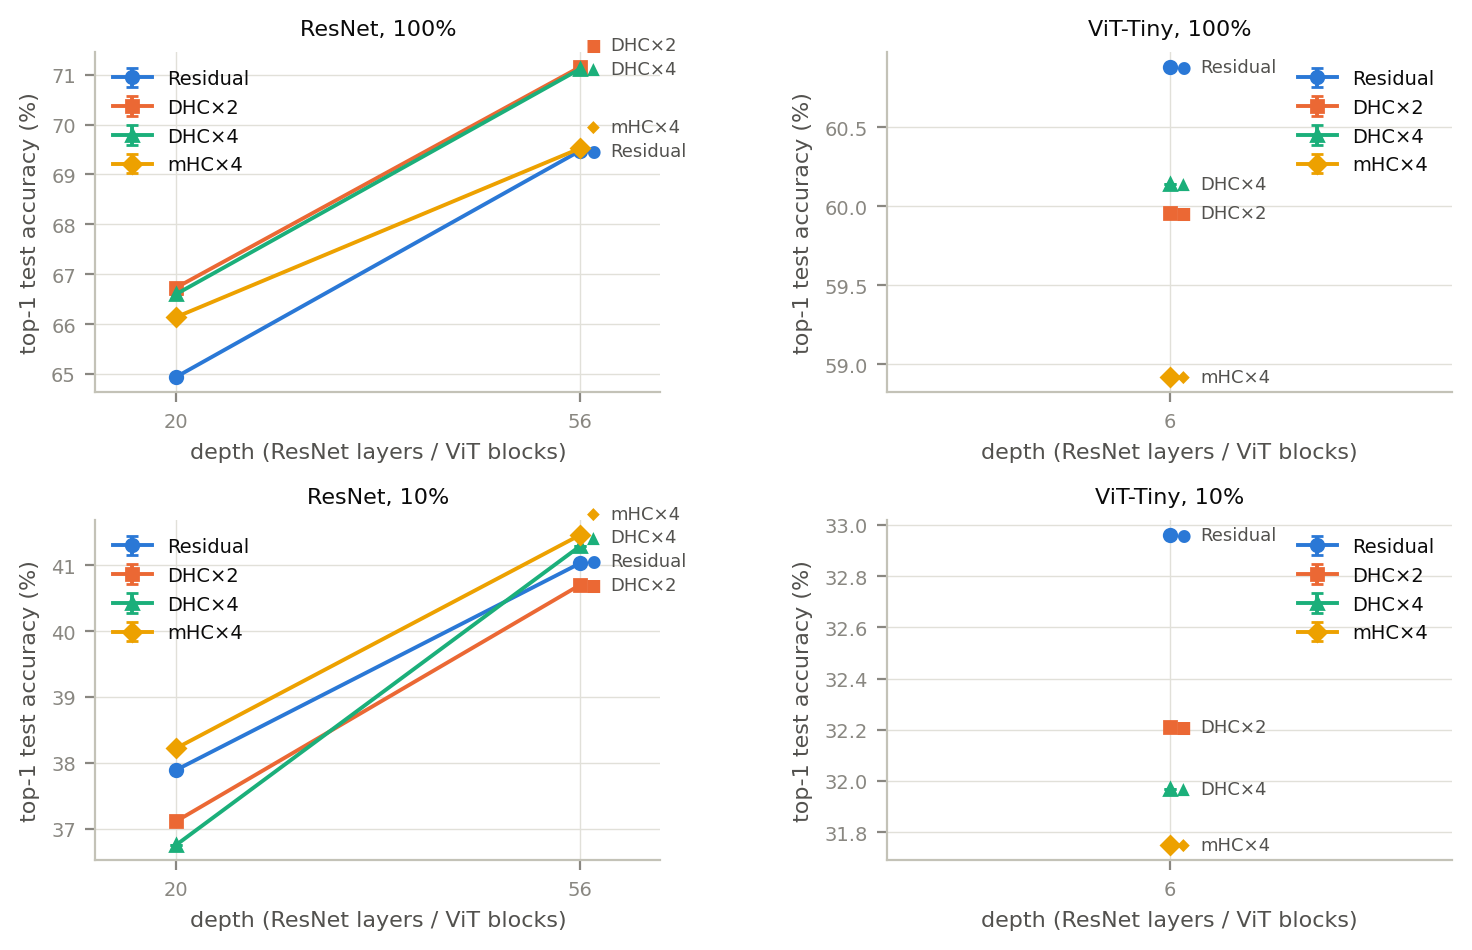

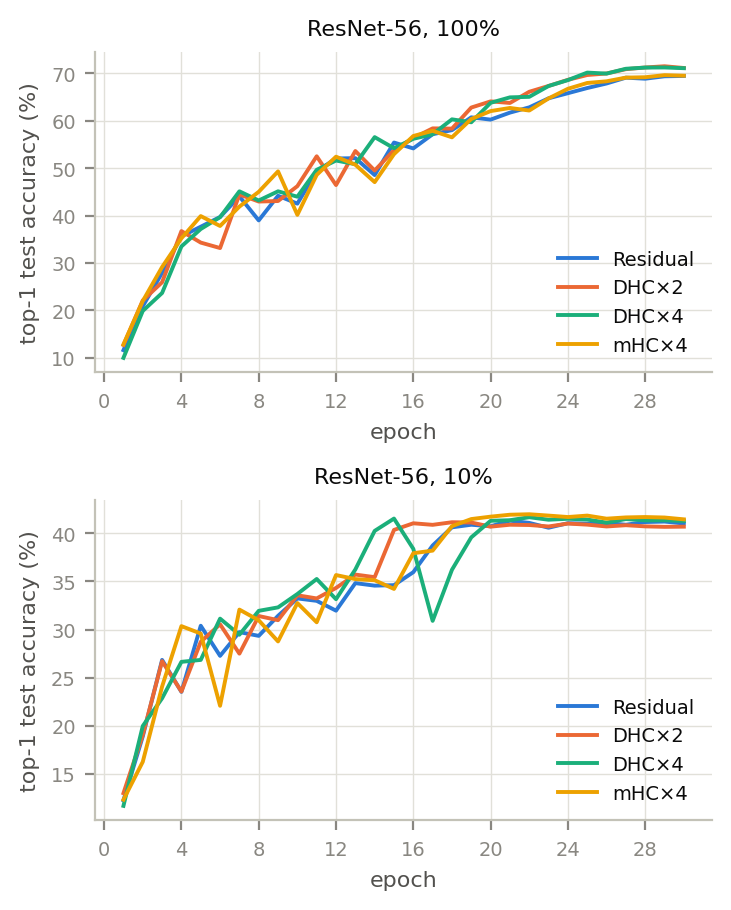

/kaggle/working/nn09/pilot_e30_analysis.zip  (1.0 MB): tables/ and figures/, to unzip into the project's results/


In [11]:
# 11 · Tables T1-T4 and figures F1-F7 from the finished runs (no GPU needed; a minute or two)
if RUN_ANALYSIS and any(RAW.glob("*/final.json")):
    try:
        import pandas as pd
        from IPython.display import Image, display

        tables_dir, figs_dir = CODE_DIR / "results/tables", CODE_DIR / "results/figures"
        costs = sorted((BASE / "timing").glob(f"cost_*__{PLAN}.csv"), key=os.path.getmtime) \
            or sorted((BASE / "timing").glob("cost_*.csv"), key=os.path.getmtime)
        COST = ["--cost", costs[-1]] if costs else []
        print("cost table:", costs[-1].name if costs else "none (tables T3 and figure F5 need cell 7 with RUN_TIMING on)")
        sh([sys.executable, "scripts/aggregate.py", "--raw", RAW, "--out", tables_dir, *COST])
        sh([sys.executable, "scripts/make_figures.py", "--raw", RAW, "--out", figs_dir, *COST])
        for f in sorted(tables_dir.glob("T1_*.csv")) + sorted(tables_dir.glob("T2_gain.csv")):
            print("\n" + f.name + " (the CSV the paper table is made from)")
            display(pd.read_csv(f).round(3))
        for name in ("F1_accuracy_vs_depth", "F7_training_curves"):
            if (figs_dir / f"{name}.png").exists():
                display(Image(filename=str(figs_dir / f"{name}.png")))
        analysis_zip = shutil.make_archive(str(BASE / f"{RUN_NAME}_analysis"), "zip", CODE_DIR / "results")
        print(f"{analysis_zip}  ({os.path.getsize(analysis_zip) / 2**20:.1f} MB): tables/ and figures/, to unzip into the project's results/")
    except Exception as e:
        print(f"WARNING: the analysis step failed ({type(e).__name__}: {e}). The run folders are untouched; send me this output.")
else:
    print("skipped (RUN_ANALYSIS is off, or no finished runs yet)")

In [12]:
# 12 · (optional, BUILD_PAPER) compile the paper draft from the tables and figures above. Needs LaTeX: installed here (2-4 min).
#      Sentences that interpret results are still marked [PENDING: ...] in red until they are written.
if BUILD_PAPER and any(RAW.glob("*/final.json")):
    if not IN_COLAB:
        print("LaTeX is installed automatically only in Colab; compile paper/ yourself with: latexmk -pdf main.tex")
    else:
        sh(["bash", "-c", "apt-get update -qq && apt-get install -y -qq texlive-publishers texlive-latex-recommended "
            "texlive-latex-extra texlive-fonts-recommended latexmk > /dev/null && echo LaTeX installed"])
        try:
            sh(["latexmk", "-pdf", "-silent", "-interaction=nonstopmode", "-f", "main.tex"], cwd=CODE_DIR / "paper")
        except RuntimeError as e:
            print("latexmk reported problems:", e)
        log = CODE_DIR / "paper/main.log"
        if log.exists():
            problems = [l for l in log.read_text(encoding="utf-8", errors="replace").splitlines() if l.startswith("!")]
            print(f"{len(problems)} LaTeX error line(s)" + (":\n" + "\n".join(problems[:15]) if problems else ""))
        pdf = CODE_DIR / "paper/main.pdf"
        if pdf.exists():
            shutil.copy(pdf, BASE / f"{RUN_NAME}_paper_draft.pdf")
            print("draft ->", BASE / f"{RUN_NAME}_paper_draft.pdf")
        else:
            print("no PDF was produced; the log above names the first error")
else:
    print("skipped (BUILD_PAPER is off, or no finished runs yet)")

skipped (BUILD_PAPER is off, or no finished runs yet)


## Bring it back into the project
1. **Executed notebook:** download it (*File ▸ Download*) and send it back; it is kept under `notebooks/executed/`.
2. **Results:** unzip `<plan>_raw.zip` (Colab: `MyDrive/<DRIVE_FOLDER>/`, Kaggle: the notebook's *Output* tab) into `results/raw/`
   (one folder per run). Keep one plan and epoch count per `results/raw/`: the analysis scripts assume all runs share their settings.
3. **Cost table:** `<DRIVE_FOLDER>/timing/cost_<gpu>__<plan>.csv` goes into `results/tables/` (T3 and F5 are made from it, and
   `python scripts/budget.py` uses it to price a plan).
4. **Tables and figures (optional):** `<plan>_analysis.zip` unzips into `results/`; they can always be rebuilt from `results/raw/`
   with `python scripts/aggregate.py && python scripts/make_figures.py`.

If anything fails, the cell output above it says where; the first thing to try is *Run all* again (runs resume).